In [4]:
import numpy as np
from scipy.optimize import curve_fit

x_data = np.array([-1, 0, 1, 2])
y_data = np.array([1.286714, 0.509169, 0.248306, 0.155943])

# Define the model function
def f(x, beta):
    return np.exp(beta[0] * x) / (beta[1] + beta[2] * x)

# Define the Jacobian function
def jacobian(x, beta):
    J = np.empty((len(x), len(beta)))
    exp_beta_x = np.exp(beta[0] * x)
    denom = beta[1] + beta[2] * x
    J[:, 0] = x * exp_beta_x / denom
    J[:, 1] = -exp_beta_x / denom**2 
    J[:, 2] = -x * exp_beta_x / denom**2
    return J

# Gauss-Newton method
def GN(Fx, Jac, x, y, beta0, maxiter=100, tol=1e-3):
    bet = beta0
    for t in range(maxiter):
        Ft = y - Fx(x, bet)
        Jt = Jac(x, bet)
        St = np.linalg.pinv(Jt.T.dot(Jt))
        yt = Jt.T.dot(Ft)
        dt = St.dot(yt)
        bet = bet + dt
        err = np.linalg.norm(yt)
        if err <= tol:
            break
    return bet, err, t

# Starting point for beta
beta0_start = np.array([-0.25, 2, 1])

# Implement Gauss-Newton method
beta_opt_GN, err_GN, iter_GN = GN(f, jacobian, x_data, y_data, beta0_start)

beta_opt_GN, err_GN, iter_GN

(array([-0.27705438,  1.97786034,  0.95277701]), 0.000743261765273997, 1)

In [12]:
# Set up the model function
def model_func(x, beta0, beta1, beta2):
    return np.exp(beta0 * x) / (beta1 + beta2 * x)

# Using curve_fit to find the optimal parameters
par_opt, par_cov = curve_fit(model_func, x_data, y_data, p0=[-0.2, 1.5, 0.8])

par_opt

array([-0.27706793,  1.97785687,  0.95275921])

In [16]:
# Given y_hat values for comparison
y_hat_1 = 0.773324
y_hat_2 = 0.108320

# Predictions using the Gauss-Newton method
y_pred_1_GN = f(-0.5, beta_opt_GN)
y_pred_2_GN = f(3, beta_opt_GN)

# Compute relative errors
e_1_GN = abs(y_pred_1_GN - y_hat_1) / abs(y_hat_1)
e_2_GN = abs(y_pred_2_GN - y_hat_2) / abs(y_hat_2)

e_1_GN, e_2_GN

(0.010802711230702398, 0.1685841521899528)

In [35]:
# Predictions at extreme values using parameters obtained from GN
y_pred_neg5 = f(-5, beta_opt_GN)
y_pred_10 = f(10, beta_opt_GN)

# Predictions at extreme values using 
beta_star = np.array([-0.25, 2, 1])
y_pred_neg5_star = f(-5, beta_star)
y_pred_10_star = f(10, beta_star)

print(y_pred_neg5, y_pred_neg5_star)
print(y_pred_10, y_pred_10_star)

-1.4342702330315673 -1.1634476524872805
0.00544324237988227 0.006840416551991566


In [31]:
# Regularization parameter
lambda_reg = 0.1

# Objective function for regularization
def objective_with_regularization(beta, x, y, lambda_reg):
    residuals = y - f(x, beta)
    return 0.5 * np.sum(residuals**2) + (lambda_reg / 2) * np.linalg.norm(beta)**2

# Gauss-Newton method to include regularization
def GN_regularized(Fx, Jac, x, y, beta0, lambda_reg, maxiter=100, tol=1e-3):
    bet = beta0
    for t in range(maxiter):
        Ft = y - Fx(x, bet)
        Jt = Jac(x, bet)
        St = np.linalg.pinv(Jt.T.dot(Jt) + lambda_reg * np.eye(len(beta0)))
        yt = Jt.T.dot(Ft)
        dt = St.dot(yt)
        bet = bet + dt
        err = np.linalg.norm(yt)
        if err <= tol:
            break
    return bet, err, t

beta_opt_GN_reg, err_GN_reg, iter_GN_reg = GN_regularized(f, jacobian, x_data, y_data, beta0_start, lambda_reg)

beta_opt_GN_reg

array([-0.25603135,  1.99462403,  0.99128772])

In [32]:
# Given y_hat values for comparison
y_hat_1 = 0.773324
y_hat_2 = 0.108320

y_pred_1_GN_reg = f(-0.5, beta_opt_GN_reg)
y_pred_2_GN_reg = f(3, beta_opt_GN_reg)

e_1_GN_reg = abs(y_pred_1_GN_reg - y_hat_1) / abs(y_hat_1)
e_2_GN_reg = abs(y_pred_2_GN_reg - y_hat_2) / abs(y_hat_2)

e_1_GN_reg, e_2_GN_reg

(0.019519134006357842, 0.13803789666506247)

In [33]:
y_pred_neg5_reg = f(-5, beta_opt_GN_reg)
y_pred_10_reg = f(10, beta_opt_GN_reg)

y_pred_neg5_reg, y_pred_neg5_star, y_pred_10_reg, y_pred_10_star

(-1.214526907738754,
 -1.1634476524872805,
 0.006490069654397626,
 0.006840416551991566)

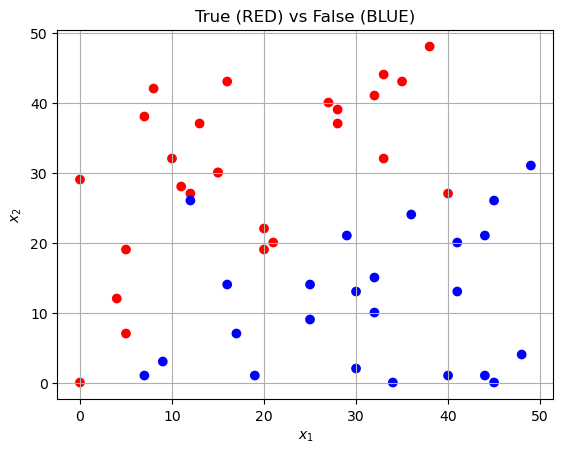

0.1


In [8]:
import numpy as np
from numpy import random as rg
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Generate dataset
n = 50
X = np.zeros((n, 2))
X[:,0] = rg.randint(0, 50, n)
X[:,1] = rg.randint(0, 50, n)
y = (X[:,1] - X[:,0] + 1 >= 0)
rid = rg.randint(0, n, int(0.05*n))
y[rid] = ~y[rid]

# Create Validation Set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

logreg = LogisticRegression(C=1e5, max_iter=int(1e5))
logreg.fit(X_train, y_train)

y_predict = logreg.predict(X_test)

# Compute test error
test_err = np.sum(np.abs(y_predict != y_test)) / len(y_test)

# Prepare to plot
import matplotlib.pyplot as plt

# Marking RED for True labels and BLUE for False label in the whole dataset
colors = np.where(y, 'r', 'b')

plt.scatter(X[:, 0], X[:, 1], c=colors)
plt.title('True (RED) vs False (BLUE)')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.grid(True)

plt.show()

print(test_err)

In [9]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear', C=1e5)
svm_model.fit(X_train, y_train)

y_predict_svm = svm_model.predict(X_test)

test_err_svm = np.sum(np.abs(y_predict_svm != y_test)) / len(y_test)

test_err_svm

0.1

In [16]:
C_values = [0.00001, 0.0001, 0.001, 0.01, 1, 10, 100]
errors = []

for C_val in C_values:
    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train, y_train)
    y_predict_svm = svm_model.predict(X_train)
    test_err_svm = np.sum(np.abs(y_predict_svm != y_train)) / len(y_train)
    errors.append(test_err_svm)

errors, C_values

([0.45, 0.15, 0.1, 0.075, 0.05, 0.05, 0.05],
 [1e-05, 0.0001, 0.001, 0.01, 1, 10, 100])

In [17]:
svm_model = SVC(kernel='linear', C=1)

svm_model.fit(X_train, y_train)

y_predict_svm = svm_model.predict(X_test)

test_err_svm = np.sum(np.abs(y_predict_svm != y_test)) / len(y_test)

test_err_svm

0.1

In [166]:
import pandas as pd
import numpy as np
from cvxopt import matrix, solvers

# Read the dataset
df = pd.read_excel('diabetes-hw4.xls')

df['Outcome'] = df['Outcome'].map({'YES': 1, 'NO': -1})

X = df.iloc[:, :-1].values
y = np.array(df['Outcome'].values)

from sklearn.svm import SVC
svm_model = SVC(kernel='linear')
svm_model.fit(X, y)

y_pred = svm_model.predict(X)

w_svm = svm_model.coef_[0]
u_svm = svm_model.intercept_[0]

print(w_svm, u_svm)

[ 0.10985904  0.01492551 -0.02462279  0.05861768  0.03856509] -4.261791420406664


In [168]:
def Qp4Svm(X, y, C):
    # dimension of variable is n+d+1
    n = X.shape[0]
    d = X.shape[1]
    
    # Form the matrix Q and vector p.
    Q = np.zeros((n+d+1, n+d+1), dtype=np.float64)  # Ensure the type is float64
    Q[0:d, 0:d] = np.eye(d)
    p = C * np.ones(n+d+1, dtype=np.float64)
    p[0:(d+1)] = 0

    # Form inequality constraints.
    G1 = -np.concatenate((np.diag(y).dot(X), y.reshape(-1, 1), np.eye(n)), axis=1)
    G2 = np.concatenate((np.zeros((n, d+1), dtype=np.float64), -np.eye(n, dtype=np.float64)), axis=1)
    G = np.concatenate((G1, G2), axis=0)
    h1 = -np.ones(n, dtype=np.float64)
    h2 = np.zeros(n, dtype=np.float64)
    h = np.concatenate((h1, h2))

    # Convert them into cvxopt matrix form, ensuring all are float64
    Q = matrix(Q)
    p = matrix(p)
    G = matrix(G)
    h = matrix(h)
    
    # Call the solver.
    sol = solvers.qp(Q, p, G, h)
    
    # Reform the outputs
    w = np.array(sol['x'][0:5])
    u = np.array(sol['x'][5])
    
    return w, u

C = 999999999999999 # hard SVM, so set an extremely large C
w, u = Qp4Svm(X, y, C)
print('Support vector:', w.ravel(), 'Intercept: ', u)

     pcost       dcost       gap    pres   dres
 0: -5.0669e+31  1.8740e+31  8e+31  2e+15  3e+01
 1:  6.3655e+30 -1.5764e+26  6e+30  5e+10  3e-03
 2:  6.3718e+28 -1.4853e+22  6e+28  5e+08  3e-05
 3:  6.3718e+26 -1.4560e+18  6e+26  5e+06  3e-07
 4:  6.3718e+24  2.9239e+16  6e+24  5e+04  3e-09
 5:  6.3718e+22  2.9388e+16  6e+22  5e+02  3e-11
 6:  6.3725e+20  2.9388e+16  6e+20  5e+00  4e-12
 7:  6.4454e+18  2.9390e+16  6e+18  5e-02  3e-12
 8:  1.3711e+17  2.9580e+16  1e+17  9e-04  3e-12
 9:  6.1801e+16  3.7567e+16  2e+16  2e-04  4e-12
10:  5.6950e+16  4.3927e+16  1e+16  7e-05  3e-12
11:  5.3994e+16  4.7139e+16  7e+15  1e-05  3e-12
12:  5.0954e+16  4.9041e+16  2e+15  3e-06  3e-12
13:  5.0172e+16  4.9592e+16  6e+14  5e-07  2e-12
14:  4.9922e+16  4.9771e+16  2e+14  1e-07  3e-13
15:  4.9846e+16  4.9823e+16  2e+13  1e-08  1e-11
16:  4.9836e+16  4.9830e+16  6e+12  3e-09  8e-12
17:  4.9833e+16  4.9832e+16  1e+12  2e-10  2e-12
18:  4.9832e+16  4.9832e+16  1e+10  2e-12  2e-11
Optimal solution foun

In [174]:
# Re-importing necessary libraries as the code execution state was reset
import numpy as np
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define different values of C to explore
C_values = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 1e1, 1e2, 1e3, 1e4]
errors = []

for C_val in C_values:
    # Initialize and fit the SVM model
    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train, y_train)
    
    # Predict on the test set
    y_predict_svm = svm_model.predict(X_train)
    
    # Calculate the test error
    test_err_svm = np.sum(np.abs(y_predict_svm != y_train)) / len(y_train)
    errors.append(test_err_svm)

errors, C_values

([0.421875,
  0.421875,
  0.328125,
  0.234375,
  0.265625,
  0.265625,
  0.265625,
  0.265625,
  0.25,
  0.28125,
  0.265625],
 [1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1, 1, 10.0, 100.0, 1000.0, 10000.0])

In [175]:

C_val = 0.001

# Initialize and fit the SVM model with C=0.0001
svm_model = SVC(kernel='linear', C=C_val)
svm_model.fit(X_train, y_train)

# Predict on the test set with the newly trained model
y_predict_svm = svm_model.predict(X_test)

# Calculate the test error
test_err_svm = np.sum(np.abs(y_predict_svm != y_test)) / len(y_test)

# Conclusion based on the test error
test_err_svm

0.5

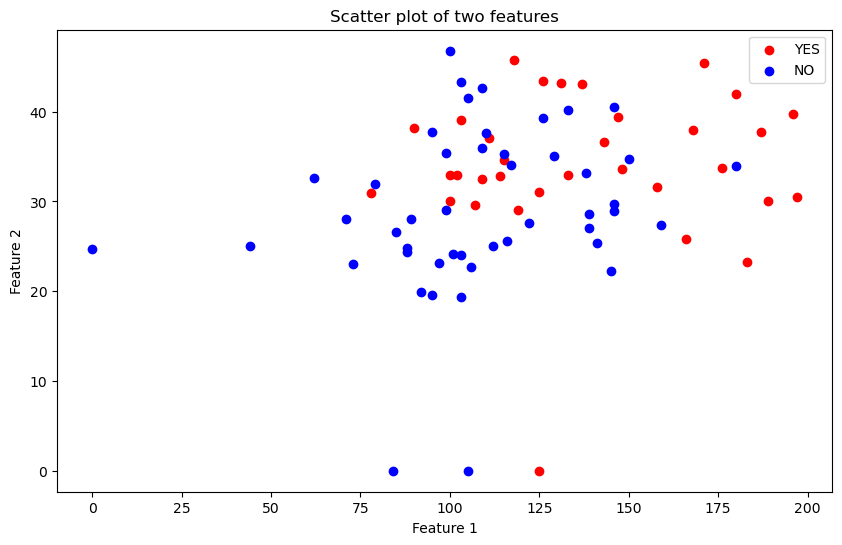

In [178]:
# Plot
plt.figure(figsize=(10, 6))
plt.scatter(X[:, 1][y == 1], X[:, 3][y == 1], color='red', label='YES')
plt.scatter(X[:, 1][y == -1], X[:, 3][y == -1], color='blue', label='NO')
plt.title('Scatter plot of two features')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()